In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
BASE = "/content/drive/MyDrive/snmp/snmpaper"
%cd {BASE}/exp3
!pip install -q -r requirements.txt

import os
os.environ["MTCSD_DIR"] = f"{BASE}/data/processed"
os.environ["EXP3_OUT"]  = "/content/drive/MyDrive/exp3_out"

/content/drive/MyDrive/snmp/snmpaper/exp3


In [3]:
!ls {BASE}/data/processed
!nvidia-smi

dataset_statistics.json  test.csv  train.csv  validation.csv
Mon Nov 16 09:45:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |           

In [4]:
!python token_stats.py


validation: 0 depth differences; 0 parent_missing rows
config.json: 100% 663/663 [00:00<00:00, 2.86MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 21.0MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 108MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 129MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 136MB/s]
count: 2176
mean: 186.85
median: 168.00
p95: 397.00
max: 616.00
share_over_512: 0.0129
share_over_768: 0.0000


In [5]:
!python run_experiment.py --model qwen --split val --scope full --limit 16 --methods none parent combined --allow-unfrozen

usage: run_experiment.py [-h] [--model {qwen,mistral,llama}]
                         [--split {validation,test}] [--scope {full,subset}]
                         [--perturb {clean,insert_start,insert_before_target,remove_parent,remove_all}]
                         [--methods METHODS [METHODS ...]]
                         [--ablation ABLATION [ABLATION ...]]
                         [--batch-size BATCH_SIZE] [--limit LIMIT]
                         [--overwrite] [--allow-unfrozen]
run_experiment.py: error: argument --split: invalid choice: 'val' (choose from 'validation', 'test')


In [6]:
!python run_experiment.py --model qwen --split validation --scope full --limit 16 --methods none parent combined --allow-unfrozen

validation: 0 depth differences; 0 parent_missing rows
modules.json: 100% 349/349 [00:00<00:00, 1.46MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 460kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 20.8MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 205kB/s]
config.json: 100% 612/612 [00:00<00:00, 2.78MB/s]

model.safetensors: downloading bytes:  84% 76.0M/90.9M [00:01<00:00, 66.7MB/s, 5.73MB/s  ]
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 43.9MB/s, 8.03MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 46.9MB/s, 8.72MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 8347.44it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 2.18MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 51.5MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 117MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 744kB/s]
config.json: 100% 190/190 [00:00<00:00, 1.06MB/s]
model.safetensors.index.json: 100% 27.8k/27.8k [

In [7]:
!python run_experiment.py -h

usage: run_experiment.py [-h] [--model {qwen,mistral,llama}]
                         [--split {validation,test}] [--scope {full,subset}]
                         [--perturb {clean,insert_start,insert_before_target,remove_parent,remove_all}]
                         [--methods METHODS [METHODS ...]]
                         [--ablation ABLATION [ABLATION ...]]
                         [--batch-size BATCH_SIZE] [--limit LIMIT]
                         [--overwrite] [--allow-unfrozen]

options:
  -h, --help            show this help message and exit
  --model {qwen,mistral,llama}
  --split {validation,test}
  --scope {full,subset}
  --perturb {clean,insert_start,insert_before_target,remove_parent,remove_all}
  --methods METHODS [METHODS ...]
  --ablation ABLATION [ABLATION ...]
  --batch-size BATCH_SIZE
  --limit LIMIT
  --overwrite
  --allow-unfrozen


In [8]:
!python tune_selector.py --model qwen --n-val 400

usage: tune_selector.py [-h] [--n-val N_VAL] [--overwrite]
tune_selector.py: error: unrecognized arguments: --model qwen


In [10]:
!python tune_selector.py --n-val 400

validation: 0 depth differences; 0 parent_missing rows
Loading weights: 100% 339/339 [01:01<00:00,  5.54it/s]
{
  "selected": {
    "alpha": 0.75,
    "beta": 0.0,
    "gamma": 0.25,
    "k": 3,
    "budget": 512,
    "scores": {
      "clean": 0.5370579833152851,
      "insert_start": 0.5206400510524222,
      "insert_before_target": 0.5248184793168686
    },
    "objective": 0.5275055045615252
  },
  "validation_ids": [
    "Biden:1-2-1-1-1",
    "Biden:1-2-3-1",
    "Biden:1-3-1",
    "Biden:1-3-1-1-1",
    "Biden:1-3-1-1-1-2",
    "Biden:1-3-1-1-1-3",
    "Biden:1-3-1-1-2-1-5",
    "Biden:1-3-1-1-2-2-2",
    "Biden:1-3-1-1-2-3",
    "Biden:1-3-1-1-5-2",
    "Biden:1-4-2-2",
    "Biden:2-2-1",
    "Biden:2-2-1-1-1",
    "Biden:2-2-1-1-1-1-2",
    "Biden:2-2-1-1-5-1",
    "Biden:2-2-1-2-3",
    "Biden:2-2-1-2-3-1",
    "Biden:2-2-2-2",
    "Biden:2-2-2-2-1",
    "Biden:2-3-1",
    "Biden:2-4-2",
    "Biden:22-1-2",
    "Biden:22-1-2-1",
    "Biden:22-1-2-1-1",
    "Biden:22-1-4",
   

In [11]:
!python run_experiment.py --model qwen --split test --scope full

test: 0 depth differences; 0 parent_missing rows
Loading weights: 100% 103/103 [00:00<00:00, 856.75it/s]
Loading weights: 100% 339/339 [01:00<00:00,  5.58it/s]


In [12]:
!ls -lh $EXP3_OUT/results/qwen/*
!wc -l $EXP3_OUT/results/qwen/*/*.jsonl

/content/drive/MyDrive/exp3_out/results/qwen/test_full:
total 5.7M
-rw------- 1 root root  985K Nov 16 12:08 clean__combined.jsonl
-rw------- 1 root root 1015K Nov 16 11:59 clean__full.jsonl
-rw------- 1 root root  991K Nov 16 11:46 clean__nearest_k.jsonl
-rw------- 1 root root  880K Nov 16 11:09 clean__none.jsonl
-rw------- 1 root root  922K Nov 16 11:26 clean__parent.jsonl
-rw------- 1 root root  995K Nov 16 12:07 clean__semantic_only.jsonl
-rw------- 1 root root   610 Nov 16 12:08 run_meta.json

/content/drive/MyDrive/exp3_out/results/qwen/validation_full:
total 21K
-rw------- 1 root root 6.6K Nov 16 09:58 clean__combined.jsonl
-rw------- 1 root root 6.0K Nov 16 09:57 clean__none.jsonl
-rw------- 1 root root 6.3K Nov 16 09:58 clean__parent.jsonl
-rw------- 1 root root  616 Nov 16 09:58 run_meta.json
   2371 /content/drive/MyDrive/exp3_out/results/qwen/test_full/clean__combined.jsonl
   2371 /content/drive/MyDrive/exp3_out/results/qwen/test_full/clean__full.jsonl
   2371 /content/dri

In [13]:
!python run_experiment.py --model mistral --split test --scope full

test: 0 depth differences; 0 parent_missing rows
config.json: 100% 601/601 [00:00<00:00, 2.57MB/s]
tokenizer_config.json: 100% 141k/141k [00:00<00:00, 201MB/s]
tokenizer.json: 100% 1.96M/1.96M [00:00<00:00, 158MB/s]

tokenizer.model: downloading bytes:   0% 0.00/587k [00:00<?, ?B/s]
tokenizer.model: downloading bytes: 100% 448k/448k [00:01<00:00, 332kB/s, 43.5kB/s  ]
tokenizer.model: reconstructing file: 100% 587k/587k [00:01<00:00, 435kB/s, 57.0kB/s  ]
special_tokens_map.json: 100% 414/414 [00:00<00:00, 1.67MB/s]
model.safetensors.index.json: 100% 23.9k/23.9k [00:00<00:00, 63.7MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0% 0/3 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/4.95G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/9.95G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   4% 615M/14.5G [00:11<04:44, 48.8MB/s, 47.7MB/s  ]
Reconstructing (incomplete total...):  12% 1.6

In [ ]:
for model in ["qwen", "mistral"]:
    for p in ["clean", "insert_start", "insert_before_target", "remove_parent", "remove_all"]:
        extra = "--ablation combined_no_semantic combined_no_structural combined_no_recency" if model == "qwen" else ""
        !python run_experiment.py --model {model} --split test --scope subset --perturb {p} {extra}

test: 0 depth differences; 0 parent_missing rows
config.json: 100% 663/663 [00:00<00:00, 2.12MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 15.7MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 73.2MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 76.5MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 86.3MB/s]
model.safetensors.index.json: 100% 27.8k/27.8k [00:00<00:00, 60.3MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0% 0/4 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/7.81G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):  11% 1.72G/15.2G [00:13<01:59, 114MB/s,  164MB/s  ]
test: 0 depth differences; 0 parent_missing rows
Traceback (most recent call last):
  File "/content/drive/MyDrive/snmp/snmpaper/exp3/run_experiment.py", line 66, in <mod

In [5]:
%cd {BASE}/exp3
!ls $EXP3_OUT/results/qwen $EXP3_OUT/results/mistral
!wc -l $EXP3_OUT/results/*/*/*.jsonl

/content/drive/MyDrive/snmp/snmpaper/exp3
/content/drive/MyDrive/exp3_out/results/mistral:
test_full

/content/drive/MyDrive/exp3_out/results/qwen:
test_full  test_subset	validation_full
    2371 /content/drive/MyDrive/exp3_out/results/mistral/test_full/clean__combined.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/mistral/test_full/clean__full.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/mistral/test_full/clean__nearest_k.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/mistral/test_full/clean__none.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/mistral/test_full/clean__parent.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/mistral/test_full/clean__semantic_only.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/qwen/test_full/clean__combined.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/qwen/test_full/clean__full.jsonl
    2371 /content/drive/MyDrive/exp3_out/results/qwen/test_full/clean__nearest_k.jsonl
    2371 /content/drive/MyDr

In [6]:
!python analyze_results.py -h
!python analyze_results.py --models qwen mistral

usage: analyze_results.py [-h] [--model MODEL] [--split SPLIT] [--scope SCOPE]

options:
  -h, --help     show this help message and exit
  --model MODEL
  --split SPLIT
  --scope SCOPE
usage: analyze_results.py [-h] [--model MODEL] [--split SPLIT] [--scope SCOPE]
analyze_results.py: error: unrecognized arguments: --models qwen mistral


In [7]:
!python analyze_results.py --model qwen
!python analyze_results.py --model mistral

In [11]:
import os
import glob
import json
import pandas as pd
from IPython.display import display

BASE = "/content/drive/MyDrive/exp3_out/results"

for model in ["qwen", "mistral"]:
    files = glob.glob(f"{BASE}/{model}/**/*.jsonl", recursive=True)

    print(f"\n{'='*60}")
    print(f"MODEL: {model.upper()} | FILES: {len(files)}")
    print("="*60)

    for file in files[:3]:
        df = pd.read_json(file, lines=True)

        print(f"\nFile: {os.path.basename(file)}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(2))


MODEL: QWEN | FILES: 48

File: clean__none.jsonl
Shape: (16, 21)
Columns: ['model', 'split', 'scope', 'perturb', 'method', 'seed', 'id', 'thread_id', 'depth', 'target', 'gold', 'pred', 'raw', 'context_ids', 'n_ancestors', 'n_chain', 'n_selected', 'n_noise_selected', 'n_in', 'n_out', 'seconds']


,model,split,scope,perturb,method,seed,id,thread_id,depth,target,...,pred,raw,context_ids,n_ancestors,n_chain,n_selected,n_noise_selected,n_in,n_out,seconds
0,qwen,validation,full,clean,none,0,Biden:1,th_00000,0,Biden,...,Favor,Favor,[],0,0,0,0,136,3,0.997387
1,qwen,validation,full,clean,none,0,Biden:1-1,th_00000,1,Biden,...,None,None,[],1,1,0,0,161,2,0.338536



File: clean__parent.jsonl
Shape: (16, 21)
Columns: ['model', 'split', 'scope', 'perturb', 'method', 'seed', 'id', 'thread_id', 'depth', 'target', 'gold', 'pred', 'raw', 'context_ids', 'n_ancestors', 'n_chain', 'n_selected', 'n_noise_selected', 'n_in', 'n_out', 'seconds']


,model,split,scope,perturb,method,seed,id,thread_id,depth,target,...,pred,raw,context_ids,n_ancestors,n_chain,n_selected,n_noise_selected,n_in,n_out,seconds
0,qwen,validation,full,clean,parent,0,Biden:1,th_00000,0,Biden,...,Favor,Favor,[],0,0,0,0,136,3,0.997387
1,qwen,validation,full,clean,parent,0,Biden:1-1,th_00000,1,Biden,...,None,None,[Biden:1],1,1,1,0,187,2,0.346318



File: clean__combined.jsonl
Shape: (16, 21)
Columns: ['model', 'split', 'scope', 'perturb', 'method', 'seed', 'id', 'thread_id', 'depth', 'target', 'gold', 'pred', 'raw', 'context_ids', 'n_ancestors', 'n_chain', 'n_selected', 'n_noise_selected', 'n_in', 'n_out', 'seconds']


,model,split,scope,perturb,method,seed,id,thread_id,depth,target,...,pred,raw,context_ids,n_ancestors,n_chain,n_selected,n_noise_selected,n_in,n_out,seconds
0,qwen,validation,full,clean,combined,0,Biden:1,th_00000,0,Biden,...,Favor,Favor,[],0,0,0,0,136,3,0.997387
1,qwen,validation,full,clean,combined,0,Biden:1-1,th_00000,1,Biden,...,None,None,[Biden:1],1,1,1,0,187,2,0.346318


... (2 outputs left out)


File: clean__parent.jsonl
Shape: (2371, 21)
Columns: ['model', 'split', 'scope', 'perturb', 'method', 'seed', 'id', 'thread_id', 'depth', 'target', 'gold', 'pred', 'raw', 'context_ids', 'n_ancestors', 'n_chain', 'n_selected', 'n_noise_selected', 'n_in', 'n_out', 'seconds']


,model,split,scope,perturb,method,seed,id,thread_id,depth,target,...,pred,raw,context_ids,n_ancestors,n_chain,n_selected,n_noise_selected,n_in,n_out,seconds
0,mistral,test,full,clean,parent,0,Biden:11,th_00002,0,Biden,...,Favor,Favor,[],0,0,0,0,159,3,1.177584
1,mistral,test,full,clean,parent,0,Biden:11-1,th_00002,1,Biden,...,Against,Against,[Biden:11],1,1,1,0,189,2,0.420169



File: clean__nearest_k.jsonl
Shape: (2371, 21)
Columns: ['model', 'split', 'scope', 'perturb', 'method', 'seed', 'id', 'thread_id', 'depth', 'target', 'gold', 'pred', 'raw', 'context_ids', 'n_ancestors', 'n_chain', 'n_selected', 'n_noise_selected', 'n_in', 'n_out', 'seconds']


,model,split,scope,perturb,method,seed,id,thread_id,depth,target,...,pred,raw,context_ids,n_ancestors,n_chain,n_selected,n_noise_selected,n_in,n_out,seconds
0,mistral,test,full,clean,nearest_k,0,Biden:11,th_00002,0,Biden,...,Favor,Favor,[],0,0,0,0,159,3,1.177584
1,mistral,test,full,clean,nearest_k,0,Biden:11-1,th_00002,1,Biden,...,Against,Against,[Biden:11],1,1,1,0,189,2,0.420169


In [12]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

BASE = "/content/drive/MyDrive/exp3_out/results"
OUT = "/content/drive/MyDrive/exp3_out/tables"

os.makedirs(OUT, exist_ok=True)

all_results = []

for model in ["qwen", "mistral"]:

    folder = f"{BASE}/{model}/test_full"

    files = glob.glob(f"{folder}/clean__*.jsonl")

    print(f"\n{model.upper()}: {len(files)} files")

    for file in files:

        df = pd.read_json(file, lines=True)

        if df.empty:
            continue

        df = df.dropna(subset=["gold", "pred"])

        metrics = {
            "model": model,
            "method": df["method"].iloc[0],
            "n": len(df),
            "accuracy": accuracy_score(df["gold"], df["pred"]),
            "precision": precision_score(
                df["gold"], df["pred"],
                average="macro", zero_division=0
            ),
            "recall": recall_score(
                df["gold"], df["pred"],
                average="macro", zero_division=0
            ),
            "macro_f1": f1_score(
                df["gold"], df["pred"],
                average="macro", zero_division=0
            ),
            "weighted_f1": f1_score(
                df["gold"], df["pred"],
                average="weighted", zero_division=0
            ),
            "avg_seconds": df["seconds"].mean()
        }

        all_results.append(metrics)

results = pd.DataFrame(all_results)

results = results.sort_values(["method", "model"])

display(results.round(4))

results.to_csv(f"{OUT}/clean_test_metrics.csv", index=False)

print("\nSaved metrics to:", OUT)


QWEN: 6 files

MISTRAL: 6 files


,model,method,n,accuracy,precision,recall,macro_f1,weighted_f1,avg_seconds
11,mistral,combined,2371,0.4517,0.3865,0.4033,0.3378,0.4263,0.6147
5,qwen,combined,2371,0.5909,0.6369,0.4937,0.5053,0.5582,0.5186
9,mistral,full,2371,0.4433,0.3838,0.3999,0.3306,0.4136,0.6672
3,qwen,full,2371,0.5884,0.6378,0.4920,0.5041,0.5560,0.5626
8,mistral,nearest_k,2371,0.4504,0.3856,0.4040,0.3368,0.4231,0.6165
2,qwen,nearest_k,2371,0.5968,0.6514,0.4989,0.5117,0.5640,0.5197
6,mistral,none,2371,0.5209,0.4051,0.4242,0.3931,0.5179,0.4481
0,qwen,none,2371,0.6019,0.6720,0.4897,0.4985,0.5560,0.3975
7,mistral,parent,2371,0.4892,0.3989,0.4205,0.3678,0.4743,0.5100
1,qwen,parent,2371,0.5934,0.6461,0.4930,0.5049,0.5582,0.4419



Saved metrics to: /content/drive/MyDrive/exp3_out/tables


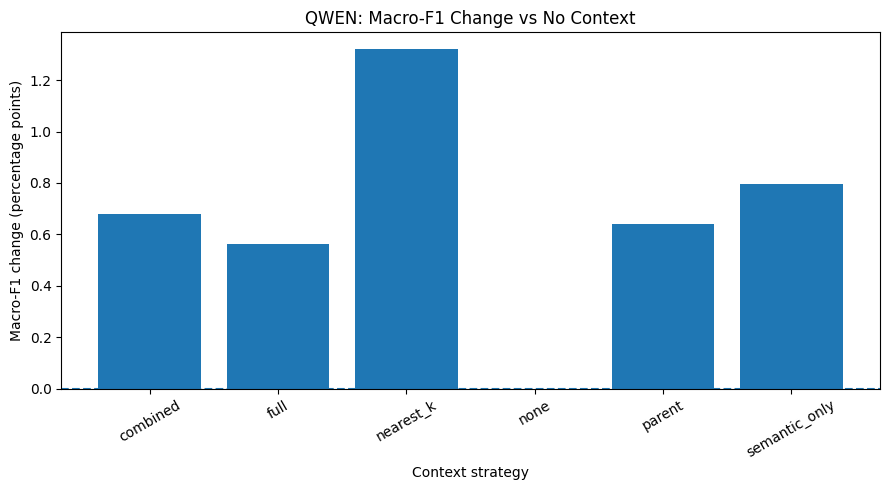

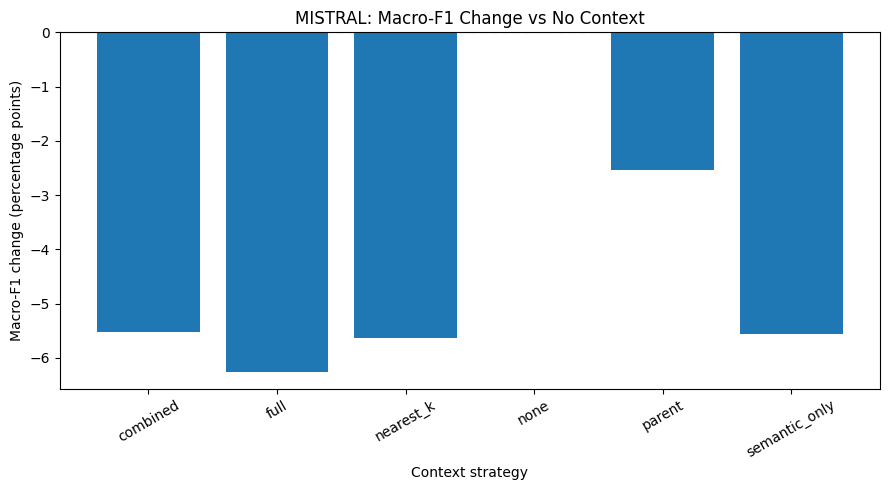

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

for model in ["qwen", "mistral"]:

    subset = results[results["model"] == model].copy()

    baseline = subset.loc[
        subset["method"] == "none", "macro_f1"
    ].iloc[0]

    subset["f1_change"] = (
        subset["macro_f1"] - baseline
    ) * 100

    plt.figure(figsize=(9, 5))

    plt.bar(subset["method"], subset["f1_change"])

    plt.axhline(0, linestyle="--")

    plt.title(f"{model.upper()}: Macro-F1 Change vs No Context")
    plt.ylabel("Macro-F1 change (percentage points)")
    plt.xlabel("Context strategy")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        f"{OUT}/{model}_context_impact.png",
        dpi=300
    )

    plt.show()

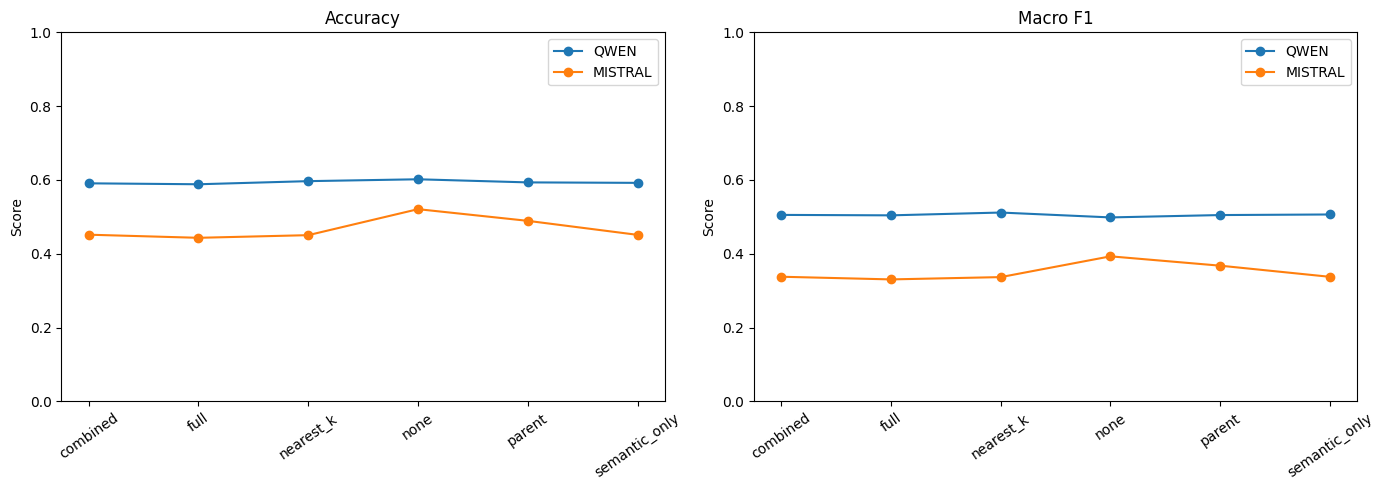

In [14]:
comparison = results.melt(
    id_vars=["model", "method"],
    value_vars=["accuracy", "macro_f1"],
    var_name="metric",
    value_name="score"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ["accuracy", "macro_f1"]):

    data = comparison[comparison["metric"] == metric]

    for model in ["qwen", "mistral"]:
        d = data[data["model"] == model]

        ax.plot(
            d["method"],
            d["score"],
            marker="o",
            label=model.upper()
        )

    ax.set_title(metric.replace("_", " ").title())
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=35)
    ax.legend()

plt.tight_layout()
plt.savefig(f"{OUT}/combined_performance.png", dpi=300)
plt.show()

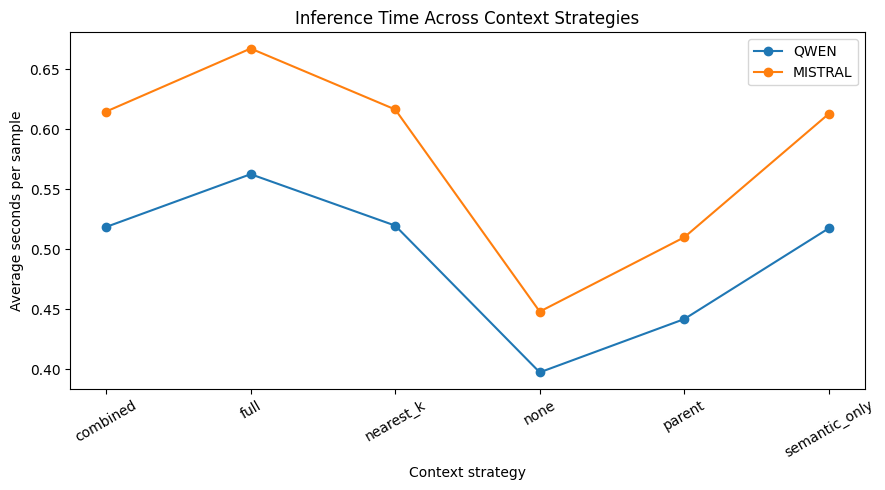

In [15]:
plt.figure(figsize=(9, 5))

for model in ["qwen", "mistral"]:
    d = results[results["model"] == model]

    plt.plot(
        d["method"],
        d["avg_seconds"],
        marker="o",
        label=model.upper()
    )

plt.title("Inference Time Across Context Strategies")
plt.xlabel("Context strategy")
plt.ylabel("Average seconds per sample")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(f"{OUT}/inference_efficiency.png", dpi=300)
plt.show()

In [16]:
from google.colab import drive
drive.mount('/content/drive')

import os
import glob
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RESULTS = "/content/drive/MyDrive/exp3_out/results"
TABLES = "/content/drive/MyDrive/exp3_out/tables"

os.makedirs(TABLES, exist_ok=True)

# Load Qwen's saved test_subset outputs
files = glob.glob(f"{RESULTS}/qwen/test_subset/*.jsonl")

frames = []
for file in files:
    df = pd.read_json(file, lines=True)
    df["source_file"] = os.path.basename(file)
    frames.append(df)

qwen_subset = pd.concat(frames, ignore_index=True)

print("Files loaded:", len(files))
print("Total records:", len(qwen_subset))
print("\nPerturbations:")
print(qwen_subset["perturb"].value_counts(dropna=False))
print("\nMethods:")
print(qwen_subset["method"].value_counts(dropna=False))
print("\nColumns:")
print(qwen_subset.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files loaded: 39
Total records: 39000

Perturbations:
perturb
insert_start            27000
clean                    9000
insert_before_target     3000
Name: count, dtype: int64

Methods:
method
none                      5000
parent                    5000
nearest_k                 5000
full                      4000
semantic_only             4000
combined                  4000
combined_no_semantic      4000
combined_no_structural    4000
combined_no_recency       4000
Name: count, dtype: int64

Columns:
['model', 'split', 'scope', 'perturb', 'method', 'seed', 'id', 'thread_id', 'depth', 'target', 'gold', 'pred', 'raw', 'context_ids', 'n_ancestors', 'n_chain', 'n_selected', 'n_noise_selected', 'n_in', 'n_out', 'seconds', 'source_file']


In [17]:
# Count records for every perturbation, method and seed
seed_summary = (
    qwen_subset
    .groupby(["perturb", "method", "seed"], dropna=False)
    .agg(
        records=("id", "count"),
        unique_examples=("id", "nunique")
    )
    .reset_index()
    .sort_values(["perturb", "method", "seed"])
)

display(seed_summary.to_string(index=False))

'             perturb                 method  seed  records  unique_examples\n               clean               combined     0     1000             1000\n               clean    combined_no_recency     0     1000             1000\n               clean   combined_no_semantic     0     1000             1000\n               clean combined_no_structural     0     1000             1000\n               clean                   full     0     1000             1000\n               clean              nearest_k     0     1000             1000\n               clean                   none     0     1000             1000\n               clean                 parent     0     1000             1000\n               clean          semantic_only     0     1000             1000\ninsert_before_target              nearest_k    11     1000             1000\ninsert_before_target                   none    11     1000             1000\ninsert_before_target                 parent    11     1000             1000

In [18]:
for method in sorted(qwen_subset["method"].unique()):

    clean_ids = set(
        qwen_subset[
            (qwen_subset["perturb"] == "clean") &
            (qwen_subset["method"] == method)
        ]["id"]
    )

    print(f"\nMethod: {method}")
    print("Clean examples:", len(clean_ids))

    for perturb in ["insert_start", "insert_before_target"]:
        subset = qwen_subset[
            (qwen_subset["perturb"] == perturb) &
            (qwen_subset["method"] == method)
        ]

        if len(subset) == 0:
            continue

        matched_ids = clean_ids.intersection(set(subset["id"]))

        print(
            f"{perturb}: {len(subset)} records | "
            f"{len(matched_ids)} matched examples"
        )


Method: combined
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples

Method: combined_no_recency
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples

Method: combined_no_semantic
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples

Method: combined_no_structural
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples

Method: full
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples

Method: nearest_k
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples
insert_before_target: 1000 records | 1000 matched examples

Method: none
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples
insert_before_target: 1000 records | 1000 matched examples

Method: parent
Clean examples: 1000
insert_start: 3000 records | 1000 matched examples
insert_before_target: 1000 records | 1000 matched examples

Method: semantic_only
Clean examples: 1000
insert_start: 3000 records | 10

In [19]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

clean = qwen_subset[
    qwen_subset["perturb"] == "clean"
].copy()

perturbed = qwen_subset[
    qwen_subset["perturb"] != "clean"
].copy()

results = []

for (perturb, method, seed), group in perturbed.groupby(
    ["perturb", "method", "seed"]
):
    clean_method = clean[clean["method"] == method]

    # Match the same examples
    matched = group.merge(
        clean_method[["id", "gold", "pred"]],
        on="id",
        suffixes=("_pert", "_clean"),
        validate="one_to_one"
    )

    if matched.empty:
        continue

    # Verify gold labels match
    assert (
        matched["gold_pert"] == matched["gold_clean"]
    ).all(), f"Gold labels differ: {method}, {seed}"

    y_true = matched["gold_pert"]
    pert_pred = matched["pred_pert"]
    clean_pred = matched["pred_clean"]

    # Metrics for perturbed predictions
    pert_acc = accuracy_score(y_true, pert_pred)
    pert_f1 = f1_score(
        y_true, pert_pred,
        average="macro", zero_division=0
    )

    # Metrics for corresponding clean predictions
    clean_acc = accuracy_score(y_true, clean_pred)
    clean_f1 = f1_score(
        y_true, clean_pred,
        average="macro", zero_division=0
    )

    # How often did the prediction change?
    change_rate = (pert_pred != clean_pred).mean()

    results.append({
        "perturbation": perturb,
        "method": method,
        "seed": seed,
        "n": len(matched),
        "clean_accuracy": clean_acc,
        "perturbed_accuracy": pert_acc,
        "accuracy_change": pert_acc - clean_acc,
        "clean_macro_f1": clean_f1,
        "perturbed_macro_f1": pert_f1,
        "macro_f1_change": pert_f1 - clean_f1,
        "prediction_change_rate": change_rate
    })

perturbation_df = pd.DataFrame(results)

perturbation_df = perturbation_df.sort_values(
    ["perturbation", "method", "seed"]
)

perturbation_df.to_csv(
    f"{TABLES}/qwen_perturbation_seed_metrics.csv",
    index=False
)

display(perturbation_df.round(4))

,perturbation,method,seed,n,clean_accuracy,perturbed_accuracy,accuracy_change,clean_macro_f1,perturbed_macro_f1,macro_f1_change,prediction_change_rate
0,insert_before_target,nearest_k,11,1000,0.528,0.507,-0.021,0.4849,0.4486,-0.0363,0.136
1,insert_before_target,none,11,1000,0.515,0.515,0.000,0.4594,0.4594,0.0000,0.000
2,insert_before_target,parent,11,1000,0.512,0.470,-0.042,0.4685,0.3790,-0.0895,0.164
3,insert_start,combined,11,1000,0.523,0.517,-0.006,0.4800,0.4691,-0.0109,0.046
4,insert_start,combined,22,1000,0.523,0.512,-0.011,0.4800,0.4656,-0.0144,0.043
5,insert_start,combined,33,1000,0.523,0.509,-0.014,0.4800,0.4586,-0.0215,0.044
6,insert_start,combined_no_recency,11,1000,0.520,0.509,-0.011,0.4770,0.4599,-0.0171,0.048
7,insert_start,combined_no_recency,22,1000,0.520,0.505,-0.015,0.4770,0.4582,-0.0188,0.047
8,insert_start,combined_no_recency,33,1000,0.520,0.508,-0.012,0.4770,0.4582,-0.0188,0.043
9,insert_start,combined_no_semantic,11,1000,0.528,0.528,0.000,0.4849,0.4833,-0.0016,0.027


In [20]:
# Compare selected context IDs between methods
import ast

def canonical_ids(value):
    if isinstance(value, str):
        try:
            value = ast.literal_eval(value)
        except:
            return value
    if isinstance(value, (list, tuple)):
        return tuple(map(str, value))
    return value

q = qwen_subset.copy()
q["context_key"] = q["context_ids"].apply(canonical_ids)

pairs = [
    ("combined", "combined_no_structural"),
    ("nearest_k", "combined_no_semantic"),
    ("semantic_only", "combined_no_recency")
]

for method_a, method_b in pairs:
    print(f"\n{method_a} vs {method_b}")

    a = q[q["method"] == method_a][
        ["perturb", "seed", "id", "context_key"]
    ]

    b = q[q["method"] == method_b][
        ["perturb", "seed", "id", "context_key"]
    ]

    matched = a.merge(
        b,
        on=["perturb", "seed", "id"],
        suffixes=("_a", "_b")
    )

    if len(matched):
        print("Matched examples:", len(matched))
        print(
            "Identical context selections:",
            (matched["context_key_a"] ==
             matched["context_key_b"]).mean()
        )


combined vs combined_no_structural
Matched examples: 4000
Identical context selections: 1.0

nearest_k vs combined_no_semantic
Matched examples: 4000
Identical context selections: 1.0

semantic_only vs combined_no_recency
Matched examples: 4000
Identical context selections: 1.0


In [21]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

depth_frames = []

for model in ["qwen", "mistral"]:
    for method in ["none", "combined"]:

        path = (
            f"{RESULTS}/{model}/test_full/"
            f"clean__{method}.jsonl"
        )

        df = pd.read_json(path, lines=True)
        df["model"] = model
        df["method"] = method
        depth_frames.append(df)

depth_data = pd.concat(depth_frames, ignore_index=True)

# Group by conversation depth
depth_data["depth_group"] = pd.cut(
    depth_data["depth"],
    bins=[-1, 1, 3, 5, float("inf")],
    labels=["0-1", "2-3", "4-5", "6+"]
)

depth_rows = []

for (model, method, depth_group), group in depth_data.groupby(
    ["model", "method", "depth_group"],
    observed=True
):
    depth_rows.append({
        "model": model,
        "method": method,
        "depth_group": str(depth_group),
        "n": len(group),
        "accuracy": accuracy_score(
            group["gold"], group["pred"]
        ),
        "macro_f1": f1_score(
            group["gold"], group["pred"],
            average="macro",
            zero_division=0
        )
    })

depth_results = pd.DataFrame(depth_rows)

depth_results.to_csv(
    f"{TABLES}/depth_wise_metrics.csv",
    index=False
)

display(
    depth_results.round(4)
)

,model,method,depth_group,n,accuracy,macro_f1
0,mistral,combined,0-1,196,0.5051,0.3738
1,mistral,combined,2-3,890,0.4978,0.3722
2,mistral,combined,4-5,862,0.4107,0.3061
3,mistral,combined,6+,423,0.4137,0.4132
4,mistral,none,0-1,196,0.5561,0.4173
5,mistral,none,2-3,890,0.5483,0.4156
6,mistral,none,4-5,862,0.5058,0.3778
7,mistral,none,6+,423,0.4775,0.3523
8,qwen,combined,0-1,196,0.5663,0.5195
9,qwen,combined,2-3,890,0.5809,0.5032


In [22]:
depth_class_distribution = (
    depth_data
    .groupby(["model", "method", "depth_group", "gold"],
             observed=True)
    .size()
    .reset_index(name="count")
)

depth_class_distribution["percentage"] = (
    depth_class_distribution["count"] /
    depth_class_distribution.groupby(
        ["model", "method", "depth_group"]
    )["count"].transform("sum") * 100
)

display(
    depth_class_distribution.round(2)
)

/tmp/ipykernel_4726/101864868.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  depth_class_distribution.groupby(


,model,method,depth_group,gold,count,percentage
0,mistral,combined,0-1,Against,59,30.10
1,mistral,combined,0-1,Favor,49,25.00
2,mistral,combined,0-1,None,88,44.90
3,mistral,combined,2-3,Against,273,30.67
4,mistral,combined,2-3,Favor,213,23.93
5,mistral,combined,2-3,None,404,45.39
6,mistral,combined,4-5,Against,270,31.32
7,mistral,combined,4-5,Favor,135,15.66
8,mistral,combined,4-5,None,457,53.02
9,mistral,combined,6+,Against,122,28.84



QWEN
              precision    recall  f1-score   support

     Against       0.61      0.42      0.50       724
       Favor       0.73      0.22      0.33       466
        None       0.57      0.84      0.68      1181

    accuracy                           0.59      2371
   macro avg       0.64      0.49      0.51      2371
weighted avg       0.62      0.59      0.56      2371



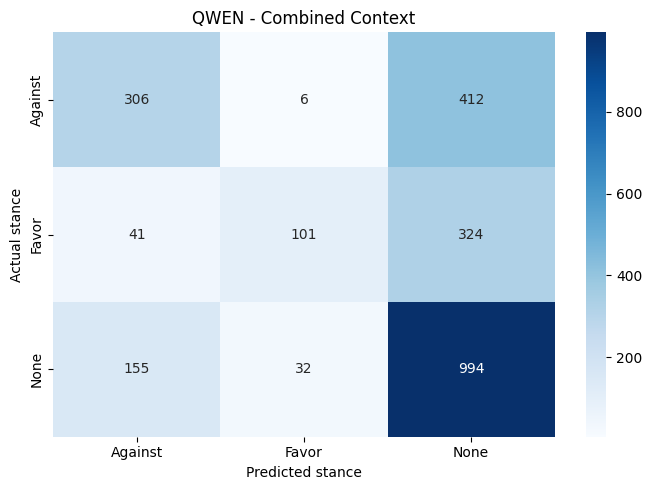


MISTRAL
              precision    recall  f1-score   support

     Against       0.49      0.63      0.55       724
       Favor       0.34      0.76      0.47       466
        None       0.72      0.22      0.33      1181

   micro avg       0.45      0.45      0.45      2371
   macro avg       0.52      0.54      0.45      2371
weighted avg       0.57      0.45      0.43      2371



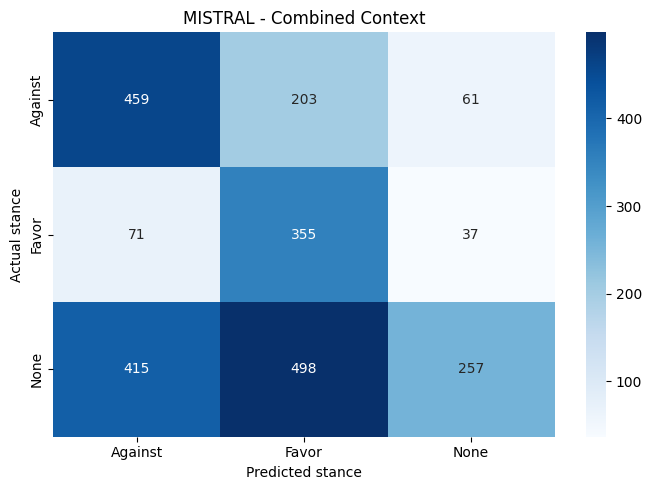

,gold,pred,count,model
0,Against,None,412,qwen
1,Favor,None,324,qwen
2,None,Against,155,qwen
3,Favor,Against,41,qwen
4,None,Favor,32,qwen
5,Against,Favor,6,qwen
6,None,Favor,498,mistral
7,None,Against,415,mistral
8,Against,Favor,203,mistral
9,Favor,Against,71,mistral


In [23]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

error_tables = []

for model in ["qwen", "mistral"]:

    path = f"{RESULTS}/{model}/test_full/clean__combined.jsonl"
    df = pd.read_json(path, lines=True)

    labels = ["Against", "Favor", "None"]

    print(f"\n{'='*45}")
    print(model.upper())
    print(f"{'='*45}")

    print(classification_report(
        df["gold"],
        df["pred"],
        labels=labels,
        zero_division=0
    ))

    cm = confusion_matrix(
        df["gold"],
        df["pred"],
        labels=labels
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.xlabel("Predicted stance")
    plt.ylabel("Actual stance")
    plt.title(f"{model.upper()} - Combined Context")
    plt.tight_layout()

    plt.savefig(
        f"{TABLES}/{model}_confusion_matrix.png",
        dpi=300
    )
    plt.show()

    # Extract misclassified examples
    errors = df[df["gold"] != df["pred"]].copy()

    confusion = (
        errors.groupby(["gold", "pred"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    confusion["model"] = model
    error_tables.append(confusion)

error_summary = pd.concat(error_tables, ignore_index=True)

error_summary.to_csv(
    f"{TABLES}/stance_error_summary.csv",
    index=False
)

display(error_summary)

In [24]:
from sklearn.metrics import classification_report
import pandas as pd

labels = ["Against", "Favor", "None"]
results = []

for model in ["qwen", "mistral"]:
    for method in ["none", "combined"]:

        path = f"{RESULTS}/{model}/test_full/clean__{method}.jsonl"
        df = pd.read_json(path, lines=True)

        df["depth_group"] = pd.cut(
            df["depth"],
            bins=[-1, 1, 3, 5, float("inf")],
            labels=["0-1", "2-3", "4-5", "6+"]
        )

        for depth, group in df.groupby("depth_group", observed=True):

            report = classification_report(
                group["gold"],
                group["pred"],
                labels=labels,
                output_dict=True,
                zero_division=0
            )

            for label in labels:
                results.append({
                    "model": model,
                    "method": method,
                    "depth": str(depth),
                    "class": label,
                    "support": report[label]["support"],
                    "precision": report[label]["precision"],
                    "recall": report[label]["recall"],
                    "f1": report[label]["f1-score"]
                })

depth_class_results = pd.DataFrame(results)

display(
    depth_class_results.sort_values(
        ["model", "depth", "class", "method"]
    )
)

depth_class_results.to_csv(
    f"{TABLES}/depth_class_metrics.csv",
    index=False
)

,model,method,depth,class,support,precision,recall,f1
36,mistral,combined,0-1,Against,59.0,0.482353,0.694915,0.569444
24,mistral,none,0-1,Against,59.0,0.516854,0.779661,0.621622
37,mistral,combined,0-1,Favor,49.0,0.475610,0.795918,0.595420
25,mistral,none,0-1,Favor,49.0,0.529412,0.734694,0.615385
38,mistral,combined,0-1,None,88.0,0.703704,0.215909,0.330435
26,mistral,none,0-1,None,88.0,0.729730,0.306818,0.432000
39,mistral,combined,2-3,Against,273.0,0.517964,0.633700,0.570016
27,mistral,none,2-3,Against,273.0,0.515152,0.684982,0.588050
40,mistral,combined,2-3,Favor,213.0,0.402010,0.751174,0.523732
28,mistral,none,2-3,Favor,213.0,0.507246,0.657277,0.572597


In [25]:

import pandas as pd
import os

os.makedirs(TABLES, exist_ok=True)

all_transitions = []
all_summaries = []
changed_examples = []

for model in ["qwen", "mistral"]:

    # Load predictions without context and with combined context
    none_path = f"{RESULTS}/{model}/test_full/clean__none.jsonl"
    combined_path = f"{RESULTS}/{model}/test_full/clean__combined.jsonl"

    df_none = pd.read_json(none_path, lines=True)
    df_combined = pd.read_json(combined_path, lines=True)

    # Match the same examples using their IDs
    assert df_none["id"].is_unique
    assert df_combined["id"].is_unique

    df = df_none.merge(
        df_combined[["id", "gold", "pred"]],
        on="id",
        suffixes=("_none", "_combined"),
        validate="one_to_one"
    )

    assert len(df) == len(df_none) == len(df_combined)
    assert (df["gold_none"] == df["gold_combined"]).all()

    df["gold"] = df["gold_none"]
    df["pred_none"] = df["pred_none"]
    df["pred_combined"] = df["pred_combined"]

    # Check whether each prediction is correct
    df["correct_none"] = df["pred_none"] == df["gold"]
    df["correct_combined"] = df["pred_combined"] == df["gold"]

    # Categorise the outcome of adding context
    def classify_transition(row):
        if row["correct_none"] and row["correct_combined"]:
            return "Correct in both"
        elif row["correct_none"] and not row["correct_combined"]:
            return "Correct -> Incorrect"
        elif not row["correct_none"] and row["correct_combined"]:
            return "Incorrect -> Correct"
        else:
            return "Incorrect in both"

    df["outcome"] = df.apply(classify_transition, axis=1)

    # Prediction transition counts
    transitions = (
        df.groupby(["pred_none", "pred_combined"], dropna=False)
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    transitions["model"] = model
    transitions["percentage"] = (
        transitions["count"] / len(df) * 100
    ).round(2)

    all_transitions.append(transitions)

    # Overall summary
    outcome_counts = df["outcome"].value_counts()

    summary = {
        "model": model,
        "total_examples": len(df),
        "unchanged_predictions": (df["pred_none"] == df["pred_combined"]).sum(),
        "changed_predictions": (df["pred_none"] != df["pred_combined"]).sum(),
        "accuracy_without_context": df["correct_none"].mean(),
        "accuracy_with_context": df["correct_combined"].mean(),
        "accuracy_change": (
            df["correct_combined"].mean() -
            df["correct_none"].mean()
        ),
        "correct_to_incorrect": outcome_counts.get(
            "Correct -> Incorrect", 0
        ),
        "incorrect_to_correct": outcome_counts.get(
            "Incorrect -> Correct", 0
        ),
        "correct_in_both": outcome_counts.get("Correct in both", 0),
        "incorrect_in_both": outcome_counts.get("Incorrect in both", 0)
    }

    all_summaries.append(summary)

    # Keep examples whose predictions changed
    changed = df[df["pred_none"] != df["pred_combined"]].copy()

    useful_columns = [
        "id", "thread_id", "depth", "gold",
        "pred_none", "pred_combined",
        "correct_none", "correct_combined"
    ]

    changed_examples.append(
        changed[[c for c in useful_columns if c in changed.columns]]
        .assign(model=model)
    )

# Combine results
transition_table = pd.concat(all_transitions, ignore_index=True)
summary_table = pd.DataFrame(all_summaries)
changed_table = pd.concat(changed_examples, ignore_index=True)

# Display
print("PREDICTION TRANSITIONS")
display(
    transition_table[
        ["model", "pred_none", "pred_combined", "count", "percentage"]
    ]
)

print("\nOVERALL IMPACT OF ADDING CONTEXT")
display(summary_table)

print("\nEXAMPLES WITH CHANGED PREDICTIONS")
display(changed_table.head(20))

# Save all outputs
transition_table.to_csv(
    f"{TABLES}/prediction_transitions.csv", index=False
)

summary_table.to_csv(
    f"{TABLES}/prediction_transition_summary.csv", index=False
)

changed_table.to_csv(
    f"{TABLES}/changed_predictions.csv", index=False
)

print("\nAll final transition analysis files saved in:", TABLES)


PREDICTION TRANSITIONS


,model,pred_none,pred_combined,count,percentage
0,qwen,None,None,1641,69.21
1,qwen,Against,Against,276,11.64
2,qwen,None,Against,216,9.11
3,qwen,Favor,Favor,94,3.96
4,qwen,Against,None,50,2.11
5,qwen,None,Favor,43,1.81
6,qwen,Favor,None,39,1.64
7,qwen,Favor,Against,10,0.42
8,qwen,Against,Favor,2,0.08
9,mistral,Against,Against,810,34.16



OVERALL IMPACT OF ADDING CONTEXT


,model,total_examples,unchanged_predictions,changed_predictions,accuracy_without_context,accuracy_with_context,accuracy_change,correct_to_incorrect,incorrect_to_correct,correct_in_both,incorrect_in_both
0,qwen,2371,2011,360,0.601856,0.590890,-0.010966,173,147,1254,797
1,mistral,2371,1724,647,0.520877,0.451708,-0.069169,322,158,913,978



EXAMPLES WITH CHANGED PREDICTIONS


,id,thread_id,depth,gold,pred_none,pred_combined,correct_none,correct_combined,model
0,Biden:11-1-1-1-1,th_00002,4,None,None,Against,True,False,qwen
1,Biden:11-1-1-1-1-1,th_00002,5,None,None,Against,True,False,qwen
2,Biden:11-1-1-1-1-2,th_00002,5,Favor,None,Against,False,False,qwen
3,Biden:11-1-1-1-1-3,th_00002,5,Favor,None,Against,False,False,qwen
4,Biden:11-1-1-1-1-4,th_00002,5,Favor,None,Against,False,False,qwen
5,Biden:11-1-1-3-2,th_00002,4,Favor,None,Against,False,False,qwen
6,Biden:11-1-2,th_00002,2,None,None,Against,True,False,qwen
7,Biden:11-1-2-1,th_00002,3,None,None,Against,True,False,qwen
8,Biden:11-1-2-1-2,th_00002,4,Favor,None,Against,False,False,qwen
9,Biden:11-1-2-1-3,th_00002,4,Favor,None,Favor,False,True,qwen



All final transition analysis files saved in: /content/drive/MyDrive/exp3_out/tables
